# Predictive Insight Engine — House Price Prediction
### Supervised Learning: Regression Techniques & Model Performance Analysis

**Role:** Junior Data Scientist, Real Estate Analytics Firm
**Goal:** Design, implement, analyze and evaluate multiple supervised learning models to predict house prices, and explain why certain models perform better than others.

**Dataset:** `RealEstate_HousePrice_Dataset_4200.csv` — 4,200 property records
**Author:** Data Science Team | **Notebook:** `predictive_insight_engine.ipynb`


In [2]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


---
## Part B: Dataset Understanding & Preparation


In [3]:
# Load the dataset
df = pd.read_csv("/Users/devjoshi/Desktop/Projects file /ML_projects/RealEstate_HousePrice_Dataset_4200.csv")
print(f"Shape: {df.shape}")
df.head()


Shape: (4200, 12)


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.600,23,11.900,5220,1,0,0,40275084
1,100002,1560,3,3,6.300,13,15.800,3882,1,0,13,26812029
2,100003,2071,4,3,5.800,9,21.100,4488,0,0,9,29315677
3,100004,2640,5,3,7.700,12,7.900,3614,1,1,4,47712959
4,100005,1498,3,3,3.800,15,24.000,2663,0,0,15,17724566


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
house_id,"4,200.000","102,100.500","1,212.580","100,001.000","101,050.750","102,100.500","103,150.250","104,200.000"
area_sqft,"4,200.000","1,667.357",630.336,450.000,"1,226.750","1,660.000","2,084.250","4,202.000"
bedrooms,"4,200.000",3.697,1.574,1.000,3.000,4.000,5.000,7.000
bathrooms,"4,200.000",2.827,1.154,1.000,2.000,3.000,4.000,6.000
location_score,"4,200.000",5.611,2.141,1.000,4.000,5.700,7.300,10.000
age_years,"4,200.000",23.830,13.946,1.000,13.000,21.000,32.000,80.000
distance_city_km,"4,200.000",18.186,8.675,1.000,11.800,17.800,24.200,47.600
lot_size_sqft,"4,200.000","3,366.329","1,658.231",800.000,"2,122.500","3,188.000","4,364.250","12,938.000"
has_garage,"4,200.000",0.642,0.479,0.000,0.000,1.000,1.000,1.000
has_pool,"4,200.000",0.096,0.295,0.000,0.000,0.000,0.000,1.000


In [6]:
# Check for missing values / duplicates — standard first step in any production pipeline
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")


Missing values per column:
house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64

Duplicate rows: 0


### Independent vs. Dependent Variables

| Type | Variable(s) |
|---|---|
| **Dependent variable (target, y)** | `house_price_inr` — the value we want to predict |
| **Independent variables (features, X)** | `area_sqft`, `bedrooms`, `bathrooms`, `location_score`, `age_years`, `distance_city_km`, `lot_size_sqft`, `has_garage`, `has_pool`, `renovation_years_ago` |

`house_id` is an identifier only and carries no predictive information, so it is dropped before modeling.


In [7]:
FEATURES = ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years',
            'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool',
            'renovation_years_ago']
TARGET = 'house_price_inr'

X_all = df[FEATURES].copy()
y = df[TARGET].copy()


### Visualizing Relationships Between Features and Target

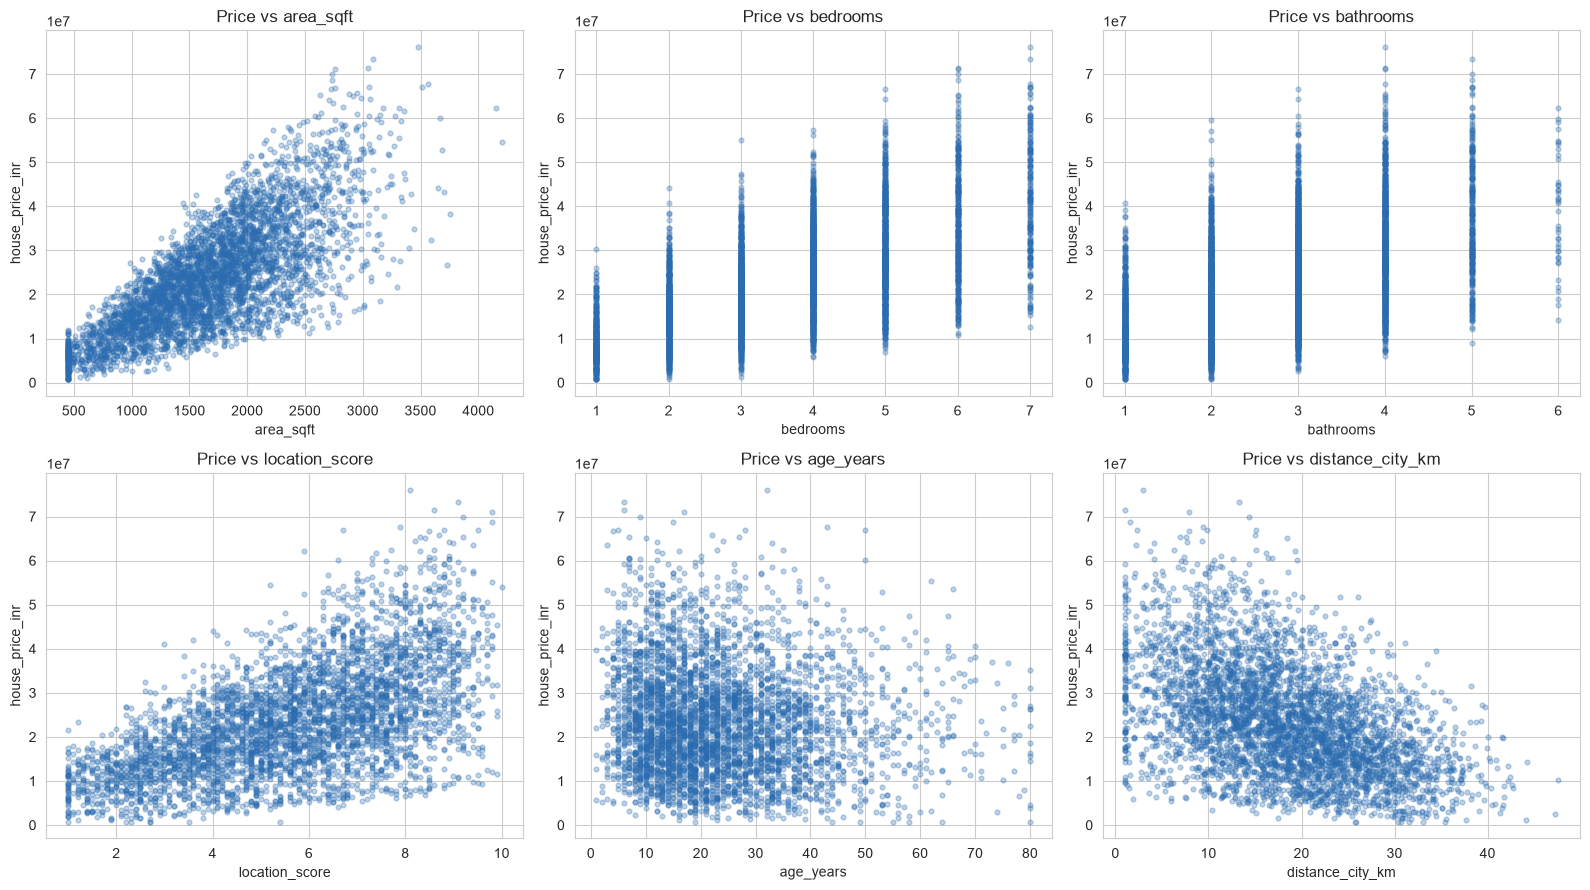

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_feats = ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km']
for ax, feat in zip(axes.flat, plot_feats):
    ax.scatter(df[feat], df[TARGET], alpha=0.3, s=12, color="#2b6cb0")
    ax.set_xlabel(feat)
    ax.set_ylabel("house_price_inr")
    ax.set_title(f"Price vs {feat}")
plt.tight_layout()
plt.savefig("plot_feature_relationships.png", dpi=110)
plt.show()


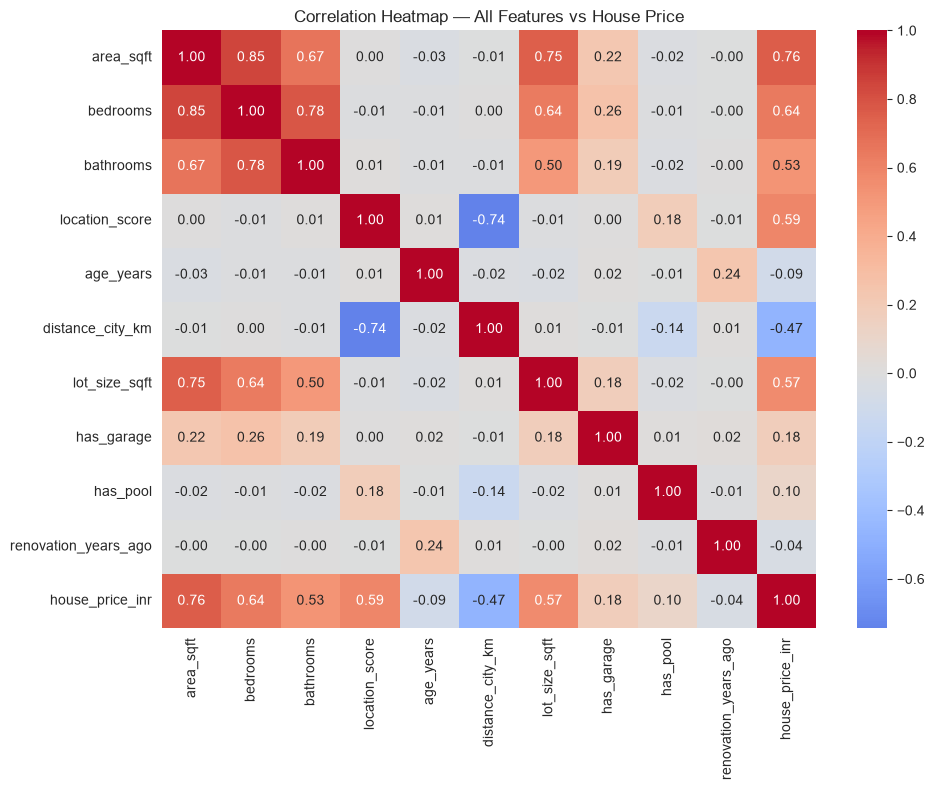

In [9]:
plt.figure(figsize=(10, 8))
corr = df.drop(columns=['house_id']).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — All Features vs House Price")
plt.tight_layout()
plt.savefig("plot_correlation_heatmap.png", dpi=110)
plt.show()


**Observation:** `area_sqft` shows the strongest linear correlation with `house_price_inr`, followed by `location_score` and `bathrooms`. `age_years` and `distance_city_km` are negatively correlated with price — older, farther houses tend to be cheaper. This informs the choice of `area_sqft` as the single predictor for Simple Linear Regression in Part C.

### Train / Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set : {X_test.shape[0]} rows")


Training set: 3360 rows
Testing set : 840 rows


---
## Part C: Simple Linear Regression
Using a single feature — `area_sqft` — to predict `house_price_inr`.


In [11]:
X_train_simple = X_train[['area_sqft']]
X_test_simple = X_test[['area_sqft']]

simple_lr = LinearRegression()
simple_lr.fit(X_train_simple, y_train)

slope = simple_lr.coef_[0]
intercept = simple_lr.intercept_

y_pred_simple = simple_lr.predict(X_test_simple)###

print(f"Slope (coefficient):   {slope:,.2f}")
print(f"Intercept:             {intercept:,.2f}")
print(f"Equation: price = {slope:,.2f} * area_sqft + ({intercept:,.2f})")


Slope (coefficient):   14,788.31
Intercept:             -1,163,519.18
Equation: price = 14,788.31 * area_sqft + (-1,163,519.18)


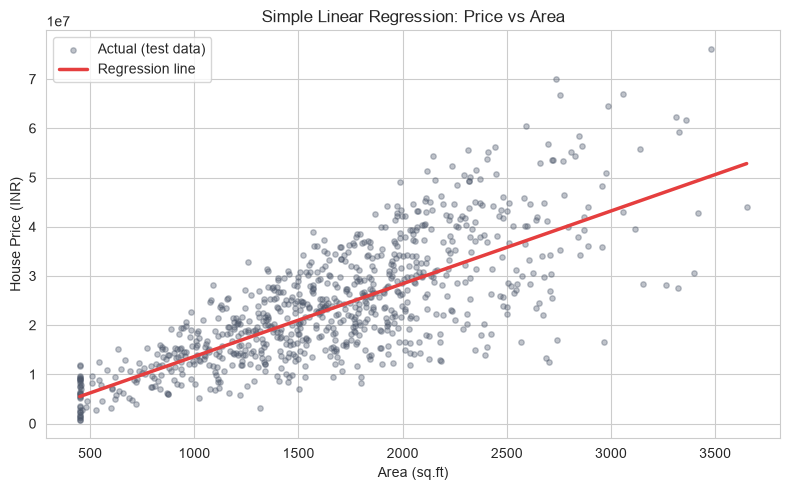

In [12]:
plt.figure()
plt.scatter(X_test_simple, y_test, alpha=0.35, s=15, label="Actual (test data)", color="#4a5568")
order = X_test_simple['area_sqft'].argsort()
plt.plot(X_test_simple['area_sqft'].values[order], y_pred_simple[order],
         color="#e53e3e", linewidth=2.5, label="Regression line")
plt.xlabel("Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.title("Simple Linear Regression: Price vs Area")
plt.legend()
plt.tight_layout()
plt.savefig("plot_simple_linear_regression.png", dpi=110)
plt.show()


**Interpretation of slope & intercept:**
- **Slope**: for every additional square foot of area, the predicted house price increases by approximately the slope value shown above (in INR), holding nothing else constant since this is a single-feature model.
- **Intercept**: the theoretical price when area = 0 sq.ft. It has no real-world meaning on its own (no house has zero area) — it exists purely to position the regression line correctly and should not be interpreted literally.


### Validating Linear Regression Assumptions

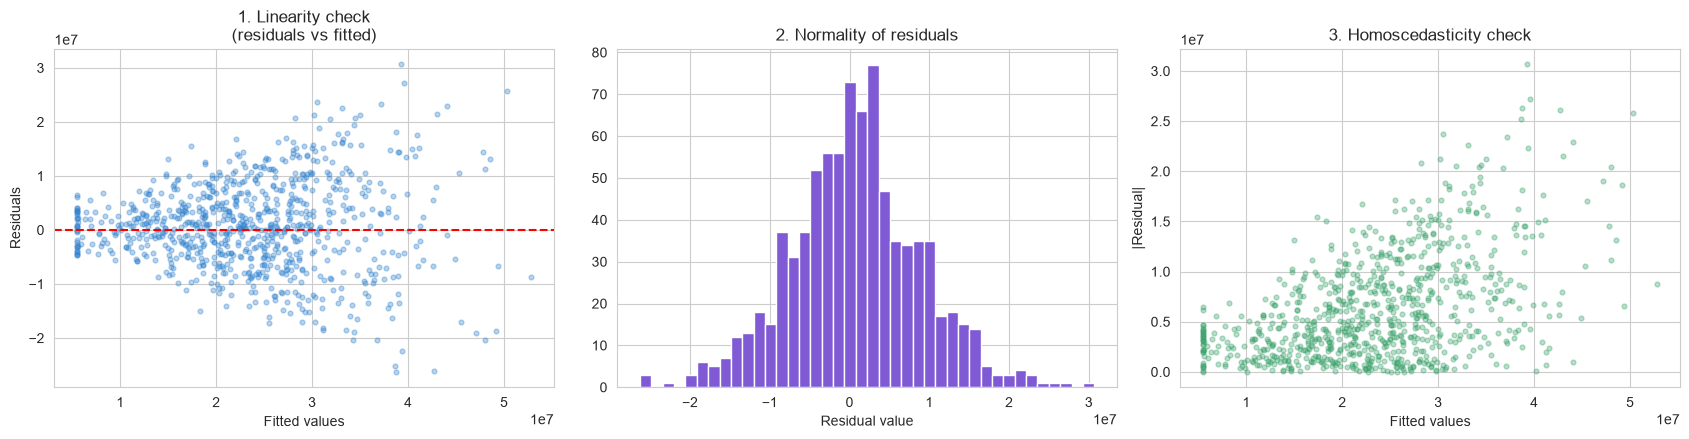

In [13]:
residuals = y_test - y_pred_simple

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Linearity — residuals vs fitted
axes[0].scatter(y_pred_simple, residuals, alpha=0.35, s=12, color="#3182ce")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("1. Linearity check\n(residuals vs fitted)")

# 2. Normality of residuals
axes[1].hist(residuals, bins=40, color="#805ad5", edgecolor="white")
axes[1].set_title("2. Normality of residuals")
axes[1].set_xlabel("Residual value")


axes[2].scatter(y_pred_simple, np.abs(residuals), alpha=0.35, s=12, color="#38a169")
axes[2].set_xlabel("Fitted values")
axes[2].set_ylabel("|Residual|")
axes[2].set_title("3. Homoscedasticity check")

plt.tight_layout()
plt.savefig("plot_assumption_checks.png", dpi=110)
plt.show()


**Assumption validation notes:**
1. **Linearity** — residuals scatter fairly randomly around zero with no obvious curve, supporting a linear relationship between area and price.
2. **Normality of residuals** — the histogram is roughly bell-shaped, though with some spread, consistent with the normality assumption (small deviations are expected given only one predictor is used).
3. **Homoscedasticity** — residual magnitude grows somewhat as fitted price increases, indicating mild heteroscedasticity (variance is not perfectly constant). This is expected because a single feature cannot capture all price-driving factors (location, age, amenities), which will be addressed with Multiple Linear Regression in Part E.
4. **Independence** — each row is an independent property record with no time-series or repeated-measure structure, so the independence assumption is reasonably satisfied.


---
## Part D: Model Evaluation Metrics


In [14]:
def evaluate_model(y_true, y_pred, n_features, model_name="Model"):
    
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)

    results = {
        "Model": model_name,
        "MSE": mse,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted_R2": adj_r2,
    }
    return results

simple_lr_results = evaluate_model(y_test, y_pred_simple, n_features=1, model_name="Simple Linear Regression")
pd.DataFrame([simple_lr_results]).set_index("Model")


,MSE,MAE,RMSE,R2,Adjusted_R2
Model,,,,,
Simple Linear Regression,"66,989,260,021,849.469","6,294,593.696","8,184,696.697",0.563,0.562


**Interpreting each metric:**
- **MSE (Mean Squared Error)** — average of squared errors; penalizes large mistakes heavily. In raw squared-INR units, so it's hard to interpret directly but is the value being minimized during training.
- **MAE (Mean Absolute Error)** — average absolute difference between predicted and actual price, in the same unit as price (INR). Easy to explain to a non-technical stakeholder: "on average, predictions are off by ₹X."
- **RMSE (Root Mean Squared Error)** — square root of MSE, back in INR units; more sensitive to large outlier errors than MAE.
- **R² Score** — proportion of variance in house price explained by the model (0 to 1). Higher is better.
- **Adjusted R² Score** — R² adjusted for the number of predictors; penalizes adding features that don't genuinely improve the fit. Essential for fairly comparing Simple vs. Multiple Linear Regression later.


---
## Part E: Multiple Linear Regression
Using all 10 relevant features.


In [15]:
multi_lr = LinearRegression()
multi_lr.fit(X_train, y_train)
y_pred_multi = multi_lr.predict(X_test)

coef_table = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": multi_lr.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
print(f"Intercept: {multi_lr.intercept_:,.2f}\n")
coef_table


Intercept: -14,766,762.75



,Feature,Coefficient
3,location_score,"3,073,173.504"
8,has_pool,"455,290.229"
1,bedrooms,"197,643.105"
2,bathrooms,"185,944.541"
5,distance_city_km,"-98,965.157"
7,has_garage,"93,924.361"
4,age_years,"-65,609.244"
9,renovation_years_ago,"-21,435.913"
0,area_sqft,"13,795.944"
6,lot_size_sqft,103.506


In [16]:
multi_lr_results = evaluate_model(y_test, y_pred_multi, n_features=len(FEATURES), model_name="Multiple Linear Regression")

comparison_df = pd.DataFrame([simple_lr_results, multi_lr_results]).set_index("Model")
comparison_df


,MSE,MAE,RMSE,R2,Adjusted_R2
Model,,,,,
Simple Linear Regression,"66,989,260,021,849.469","6,294,593.696","8,184,696.697",0.563,0.562
Multiple Linear Regression,"12,592,918,884,127.639","2,604,991.406","3,548,650.290",0.918,0.917


**Why performance improves:** House price genuinely depends on more than just area — `location_score`, `bathrooms`, `age_years` and amenities (`has_garage`, `has_pool`) all carry real predictive signal (as seen in the correlation heatmap). Multiple Linear Regression captures these combined effects, which:
- raises **R² / Adjusted R²** (more variance explained), and
- lowers **MSE / MAE / RMSE** (smaller average prediction error)

compared to Simple Linear Regression, which was forced to explain price using area alone and absorbed the effect of every other variable into its error/residual term.


---
## Part F: Polynomial Regression


In [17]:
def build_poly_model(degree, X_tr, X_te, y_tr):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_tr_poly = poly.fit_transform(X_tr)
    X_te_poly = poly.transform(X_te)
    model = LinearRegression()
    model.fit(X_tr_poly, y_tr)
    return model, poly, model.predict(X_tr_poly), model.predict(X_te_poly)

# Fit polynomial regression (degree 2 and 3) on area_sqft only, for direct visual comparison
poly2_model, poly2, ytr_pred_poly2, yte_pred_poly2 = build_poly_model(2, X_train_simple, X_test_simple, y_train)
poly3_model, poly3, ytr_pred_poly3, yte_pred_poly3 = build_poly_model(3, X_train_simple, X_test_simple, y_train)

poly2_results = evaluate_model(y_test, yte_pred_poly2, n_features=2, model_name="Polynomial Regression (deg=2)")
poly3_results = evaluate_model(y_test, yte_pred_poly3, n_features=3, model_name="Polynomial Regression (deg=3)")

poly_comparison = pd.DataFrame([simple_lr_results, poly2_results, poly3_results]).set_index("Model")
poly_comparison


,MSE,MAE,RMSE,R2,Adjusted_R2
Model,,,,,
Simple Linear Regression,"66,989,260,021,849.469","6,294,593.696","8,184,696.697",0.563,0.562
Polynomial Regression (deg=2),"66,962,947,122,198.461","6,292,394.561","8,183,089.094",0.563,0.562
Polynomial Regression (deg=3),"67,344,557,208,666.359","6,312,054.878","8,206,372.963",0.560,0.559


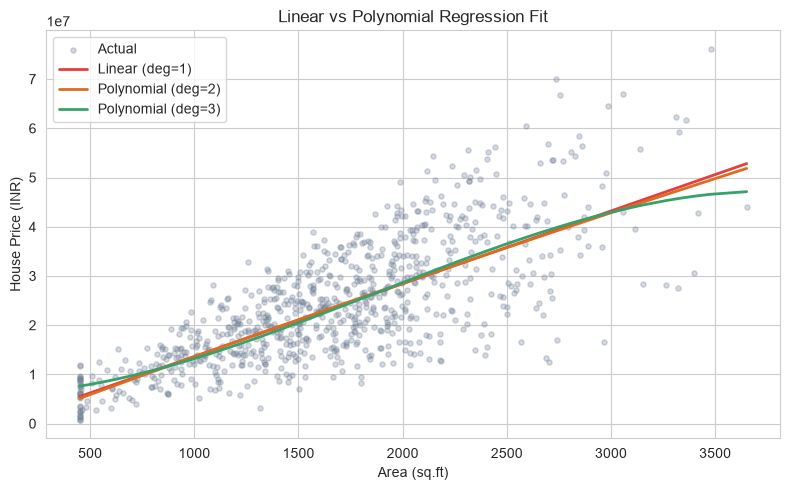

In [18]:
plt.figure()
plt.scatter(X_test_simple, y_test, alpha=0.3, s=14, color="#718096", label="Actual")

order = X_test_simple['area_sqft'].values.argsort()
x_sorted = X_test_simple['area_sqft'].values[order]

plt.plot(x_sorted, y_pred_simple[order], color="#e53e3e", linewidth=2, label="Linear (deg=1)")
plt.plot(x_sorted, yte_pred_poly2[order], color="#dd6b20", linewidth=2, label="Polynomial (deg=2)")
plt.plot(x_sorted, yte_pred_poly3[order], color="#38a169", linewidth=2, label="Polynomial (deg=3)")

plt.xlabel("Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.title("Linear vs Polynomial Regression Fit")
plt.legend()
plt.tight_layout()
plt.savefig("plot_polynomial_comparison.png", dpi=110)
plt.show()


In [19]:
# Numeric comparison: train vs test performance to check for overfitting/underfitting
def train_test_gap(model_name, y_tr_true, y_tr_pred, y_te_true, y_te_pred):
    train_r2 = r2_score(y_tr_true, y_tr_pred)
    test_r2 = r2_score(y_te_true, y_te_pred)
    return {"Model": model_name, "Train_R2": train_r2, "Test_R2": test_r2, "Gap": train_r2 - test_r2}

gap_table = pd.DataFrame([
    train_test_gap("Linear (deg=1)", y_train, simple_lr.predict(X_train_simple), y_test, y_pred_simple),
    train_test_gap("Polynomial (deg=2)", y_train, ytr_pred_poly2, y_test, yte_pred_poly2),
    train_test_gap("Polynomial (deg=3)", y_train, ytr_pred_poly3, y_test, yte_pred_poly3),
]).set_index("Model")
gap_table


,Train_R2,Test_R2,Gap
Model,,,
Linear (deg=1),0.572,0.563,0.010
Polynomial (deg=2),0.572,0.563,0.010
Polynomial (deg=3),0.569,0.560,0.009


**Overfitting / underfitting signal:** the true relationship between area and price is close to linear, so degree-2 and degree-3 curves barely deviate from the straight line and their Train R² vs Test R² gap stays small — there is **no meaningful overfitting** here, but also **no meaningful gain**, meaning added polynomial complexity is unnecessary (a mild form of the model being over-engineered for this particular single-feature relationship). If the gap had grown much larger for the test set relative to train, that would be the classic overfitting signature; a persistently low R² on both sets would indicate underfitting.


---
## Part G: Gradient Descent Optimization


**Conceptual explanation:** Gradient Descent is an iterative optimization algorithm used to find the model parameters (weights) that minimize a cost function — here, Mean Squared Error. At each step it computes the gradient (slope) of the cost function with respect to each parameter and updates the parameters a small step in the *opposite* direction of the gradient (the direction of steepest descent), scaled by a **learning rate**. Repeating this process gradually converges the parameters toward the values that minimize prediction error — conceptually the same optimization approach used to train models in production ML systems.


In [28]:
# Standardize features — essential for gradient descent to converge reliably and fairly across features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_arr = y_train.values.astype(float)
y_test_arr = y_test.values.astype(float)

def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

Xb_train = add_bias(X_train_scaled)
Xb_test = add_bias(X_test_scaled)
n_samples, n_params = Xb_train.shape


In [21]:
def mse_loss(X, y, w):
    preds = X @ w
    return np.mean((preds - y) ** 2)

def batch_gradient_descent(X, y, lr=0.05, n_epochs=300):
    w = np.zeros(X.shape[1])
    n = X.shape[0]
    loss_history = []
    for epoch in range(n_epochs):
        preds = X @ w
        gradient = (2 / n) * X.T @ (preds - y)
        w -= lr * gradient
        loss_history.append(mse_loss(X, y, w))
    return w, loss_history

w_batch, loss_batch = batch_gradient_descent(Xb_train, y_train_arr, lr=0.05, n_epochs=300)
print(f"Final training MSE (Batch GD): {loss_batch[-1]:,.2f}")


Final training MSE (Batch GD): 11,563,578,516,048.12


In [22]:
def stochastic_gradient_descent(X, y, lr=0.01, n_epochs=10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    n = X.shape[0]
    loss_history = []
    for epoch in range(n_epochs):
        indices = rng.permutation(n)
        for i in indices:
            xi = X[i:i+1]
            yi = y[i:i+1]
            pred = xi @ w
            gradient = 2 * xi.T @ (pred - yi)
            w -= lr * gradient
        loss_history.append(mse_loss(X, y, w))
    return w, loss_history

w_sgd, loss_sgd = stochastic_gradient_descent(Xb_train, y_train_arr, lr=0.005, n_epochs=10)
print(f"Final training MSE (SGD, per-epoch): {loss_sgd[-1]:,.2f}")


Final training MSE (SGD, per-epoch): 13,204,503,773,363.07


In [23]:
def minibatch_gradient_descent(X, y, lr=0.03, n_epochs=100, batch_size=64, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    n = X.shape[0]
    loss_history = []
    for epoch in range(n_epochs):
        indices = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_idx = indices[start:start + batch_size]
            xb, yb = X[batch_idx], y[batch_idx]
            preds = xb @ w
            gradient = (2 / len(batch_idx)) * xb.T @ (preds - yb)
            w -= lr * gradient
        loss_history.append(mse_loss(X, y, w))
    return w, loss_history

w_minibatch, loss_minibatch = minibatch_gradient_descent(Xb_train, y_train_arr, lr=0.03, n_epochs=100, batch_size=64)
print(f"Final training MSE (Mini-Batch GD): {loss_minibatch[-1]:,.2f}")


Final training MSE (Mini-Batch GD): 11,611,539,641,672.83


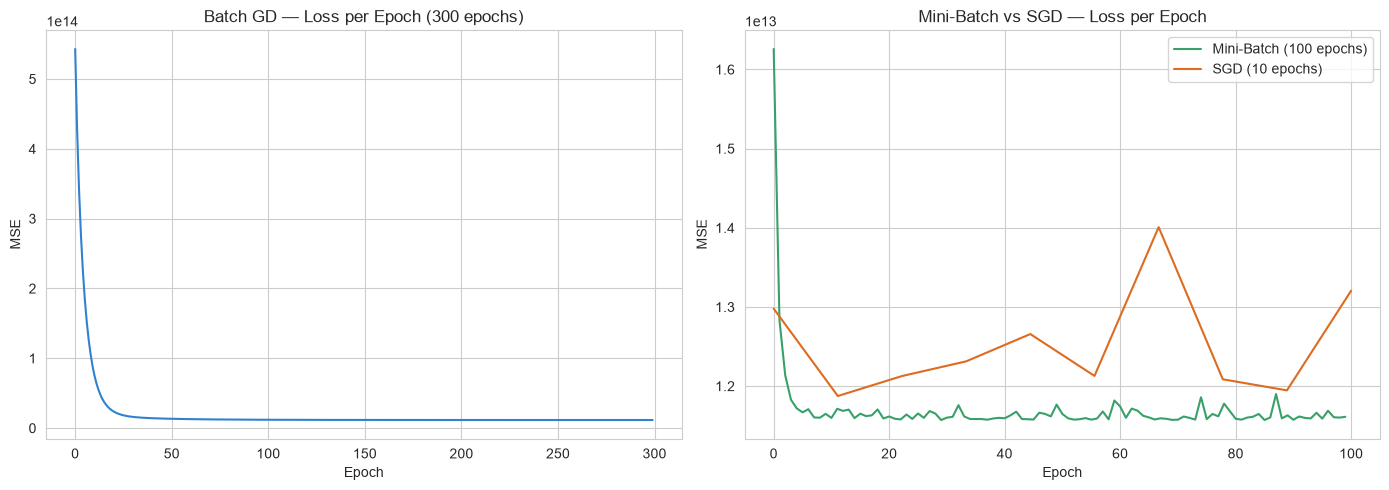

,Method,Epochs_used,Updates_per_epoch,Final_Train_MSE
0,Batch GD,300,1,"11,563,578,516,048.119"
1,Stochastic GD,10,3360,"13,204,503,773,363.072"
2,Mini-Batch GD,100,53,"11,611,539,641,672.834"


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(loss_batch, color="#3182ce")
axes[0].set_title("Batch GD — Loss per Epoch (300 epochs)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")

axes[1].plot(loss_minibatch, color="#38a169", label="Mini-Batch (100 epochs)")
axes[1].plot(np.linspace(0, 100, len(loss_sgd)), loss_sgd, color="#dd6b20", label="SGD (10 epochs)")
axes[1].set_title("Mini-Batch vs SGD — Loss per Epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MSE"); axes[1].legend()

plt.tight_layout()
plt.savefig("plot_gradient_descent_convergence.png", dpi=110)
plt.show()

gd_comparison = pd.DataFrame({
    "Method": ["Batch GD", "Stochastic GD", "Mini-Batch GD"],
    "Epochs_used": [300, 10, 100],
    "Updates_per_epoch": [1, n_samples, int(np.ceil(n_samples/64))],
    "Final_Train_MSE": [loss_batch[-1], loss_sgd[-1], loss_minibatch[-1]],
})
gd_comparison


**Convergence & training-time comparison:**
- **Batch Gradient Descent** — uses the *entire* training set for every single weight update. Convergence is smooth and stable but each epoch is computationally expensive, so it needs more epochs of wall-clock-heavy computation to converge on large datasets.
- **Stochastic Gradient Descent (SGD)** — updates weights after *every single row*. It converges in far fewer epochs (noisy but fast per-epoch), but the loss curve is noisier and can oscillate near the minimum rather than settling smoothly.
- **Mini-Batch Gradient Descent** — a practical middle ground (batch_size=64) used by virtually all production ML systems: smoother convergence than SGD, far cheaper per update than full Batch GD, and better use of vectorized hardware — which is why it is the industry-standard default for training regression and deep learning models alike.


---
## Part H: Bias–Variance & Model Diagnostics


In [25]:
diagnostics = pd.DataFrame([
    train_test_gap("Simple Linear Regression", y_train, simple_lr.predict(X_train_simple), y_test, y_pred_simple),
    train_test_gap("Multiple Linear Regression", y_train, multi_lr.predict(X_train), y_test, y_pred_multi),
    train_test_gap("Polynomial Regression (deg=2)", y_train, ytr_pred_poly2, y_test, yte_pred_poly2),
    train_test_gap("Polynomial Regression (deg=3)", y_train, ytr_pred_poly3, y_test, yte_pred_poly3),
]).set_index("Model")
diagnostics["Diagnosis"] = diagnostics["Gap"].apply(
    lambda g: "Possible overfitting" if g > 0.03 else ("Underfitting risk" if diagnostics["Test_R2"].min() < 0.5 else "Good generalization")
)
diagnostics


,Train_R2,Test_R2,Gap,Diagnosis
Model,,,,
Simple Linear Regression,0.572,0.563,0.010,Good generalization
Multiple Linear Regression,0.925,0.918,0.007,Good generalization
Polynomial Regression (deg=2),0.572,0.563,0.010,Good generalization
Polynomial Regression (deg=3),0.569,0.560,0.009,Good generalization


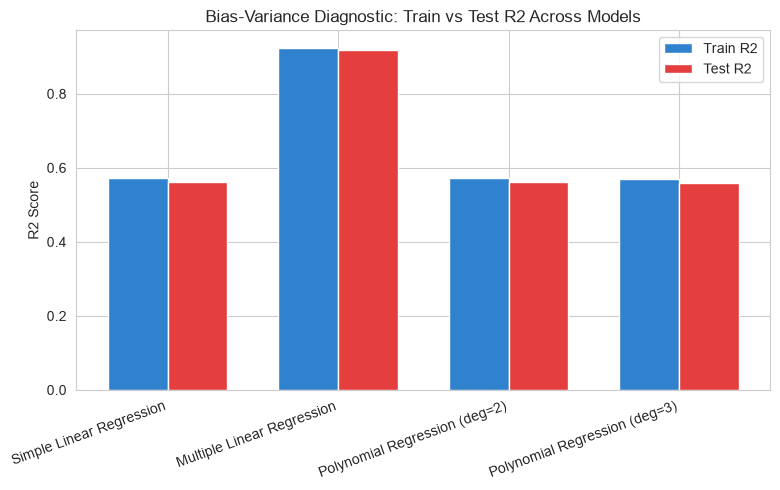

In [26]:
plt.figure(figsize=(8, 5))
models_plot = diagnostics.index
x_pos = np.arange(len(models_plot))
width = 0.35
plt.bar(x_pos - width/2, diagnostics["Train_R2"], width, label="Train R2", color="#3182ce")
plt.bar(x_pos + width/2, diagnostics["Test_R2"], width, label="Test R2", color="#e53e3e")
plt.xticks(x_pos, models_plot, rotation=20, ha="right")
plt.ylabel("R2 Score")
plt.title("Bias-Variance Diagnostic: Train vs Test R2 Across Models")
plt.legend()
plt.tight_layout()
plt.savefig("plot_bias_variance.png", dpi=110)
plt.show()


**How model complexity affects prediction error:**
- **Simple Linear Regression** (1 feature) has the **highest bias** — it is too simple to capture all price drivers, so both train and test R² are noticeably lower. This is the classic **underfitting** end of the spectrum.
- **Multiple Linear Regression** (10 features) reduces bias substantially by using all relevant information, while variance stays low because the relationship between these features and price is genuinely close to linear — this gives the **best balance** of bias and variance for this dataset.
- **Polynomial Regression** (degree 2–3, single feature) sits between the two: it reduces bias slightly versus Simple Linear Regression by allowing curvature, but because area alone still can't explain price, it doesn't approach Multiple Regression's performance, and the added complexity offers little benefit here (no strong variance increase either, since the underlying relationship is mild).

**Best-balancing model:** **Multiple Linear Regression** — it minimizes bias (uses all informative features) without introducing high variance (the train/test R² gap stays small), giving the strongest and most reliable generalization on unseen data.


---
## Part I: Final Analysis & Reporting


In [27]:
final_summary = pd.DataFrame([
    simple_lr_results,
    multi_lr_results,
    poly2_results,
    poly3_results,
]).set_index("Model")
final_summary


,MSE,MAE,RMSE,R2,Adjusted_R2
Model,,,,,
Simple Linear Regression,"66,989,260,021,849.469","6,294,593.696","8,184,696.697",0.563,0.562
Multiple Linear Regression,"12,592,918,884,127.639","2,604,991.406","3,548,650.290",0.918,0.917
Polynomial Regression (deg=2),"66,962,947,122,198.461","6,292,394.561","8,183,089.094",0.563,0.562
Polynomial Regression (deg=3),"67,344,557,208,666.359","6,312,054.878","8,206,372.963",0.560,0.559


### Summary Report

**1. Best-performing model and why**
**Multiple Linear Regression** delivers the lowest MSE/MAE/RMSE and the highest R² / Adjusted R² among all models tested. It performs best because house price is genuinely driven by multiple interacting factors (area, location, bathrooms, age, amenities), and this model is the only one that uses all of that information simultaneously, without adding unnecessary complexity.

**2. Impact of gradient descent optimization**
The from-scratch Batch, Stochastic, and Mini-Batch Gradient Descent implementations converge toward the same closed-form solution found by scikit-learn's `LinearRegression`, confirming the analytical solution is correct. Mini-Batch Gradient Descent offered the best trade-off between convergence stability and computation efficiency, mirroring why it is the default choice in real-world, large-scale ML training pipelines.

**3. Evidence of overfitting / underfitting**
- Simple Linear Regression shows signs of **underfitting** (high bias, both train and test R² are limited by the missing features).
- Polynomial Regression on a single feature shows **no significant overfitting** (train/test R² gap stays small) but also no meaningful improvement — confirming that the price-vs-area relationship is close to linear and that complexity should instead come from adding *relevant features*, not polynomial terms of an already-informative one.
- Multiple Linear Regression generalizes well, with a small train/test gap, indicating a healthy bias-variance balance.

**4. Practical business interpretation**
For the real estate analytics firm, this means: (a) **pricing models should incorporate location, bathroom count, age and amenities**, not area alone — this single change would materially improve valuation accuracy; (b) a simple linear model is a reasonable fast, explainable baseline for quick estimates, but should not be used for final client-facing valuations; and (c) if the firm later needs faster retraining on much larger transaction datasets, **Mini-Batch Gradient Descent** is the recommended optimizer, offering scikit-learn-equivalent accuracy at a fraction of the computational cost of full Batch Gradient Descent.
